In [1]:
# Set cwd
import os
os.chdir('/scratch/pompeii/elferich/gouaux_tomo/ProcessingJE/manuscript01/relion_reconstruction')
TILTSERIES = 'culled_ts/20231017_EGmilled24-2_60_culled.mrc'
TOMOGRAM= '20231017_EGmilled24-2_60'
AUNP_FILE = 'finding_ampa/pipeline_data/pipeline1/visualization/20231017_EGmilled24-2_60/combined_aunp.txt'
PARAS = 'ImportTomo/job002/centered.star'
TILT = 5

# Refinement algorithm
- Pick AuNPs in SNR100 tomogram, individually in ROIs
- Find shifts
- Align angles
- Repick AuNPS
- Find shifts
- Align angles

/groups/elferich/.conda/envs/findingampa/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3526.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


tensor([0, 0], device='cuda:0')


/groups/elferich/Documents/findingampa/src/findingampa/utils/projection.py:48: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at ../aten/src/ATen/native/Convolution.cpp:1008.)
  projection = F.conv2d(projection[None,None],circle[None,None],padding='same')


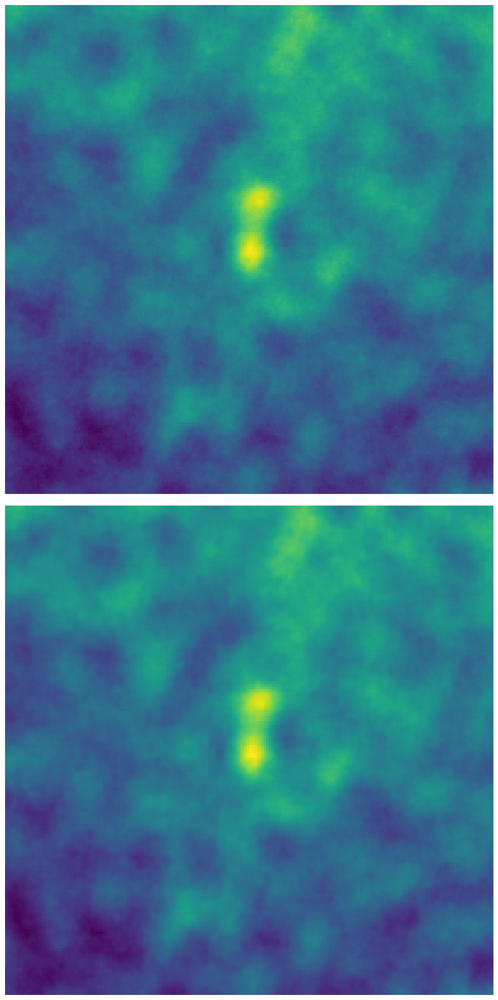

In [2]:

from findingampa.utils.transforms import load_relion_matrices
from findingampa.utils.projection import load_aunps, project_aunp_model_mine, project_aunp_model_libtilt
import mrcfile
import torch
import starfile
import matplotlib.pyplot as plt
plot=True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
tomogram_infos = starfile.read(PARAS)

tomogram_info = tomogram_infos["global"][tomogram_infos["global"]["rlnTomoName"] == TOMOGRAM].iloc[0]
tilt_info = tomogram_infos[TOMOGRAM]

matrices = load_relion_matrices(tilt_info, device)

aunps = load_aunps(AUNP_FILE, device)
tilt_series = torch.as_tensor(mrcfile.read(tomogram_info["rlnTomoTiltSeriesName"]),device=device)

if plot:
    # Arrange len(matrices) subplots in a
    fig, axs = plt.subplots(2, 1, figsize=(10, 20)) 

for i in [TILT]:
    model_image = project_aunp_model_mine(aunps, matrices[i], tilt_series.shape[1:], 8.3, device)
    image_product = torch.fft.fft2(tilt_series[i]) * torch.fft.fft2(model_image).conj()
    cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
    sub_orig = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
    peak_pos = (sub_orig==torch.max(sub_orig)).nonzero()
    shift = (peak_pos-torch.tensor([100,100],device=device))[0]
    print(shift)
    matrices[i][0,3] += shift[1]
    matrices[i][1,3] += shift[0]
    model_image,circ = project_aunp_model_libtilt(aunps, matrices[i], tilt_series.shape[1:], 8.3, device)
    model_image = model_image * -1.0
    image_product = torch.fft.fft2(tilt_series[i]) * torch.fft.fft2(model_image).conj()
    cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
    sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
    if plot:
        axs[0].imshow(sub_orig.cpu().detach())
        axs[1].imshow(sub_new.cpu().detach())
        # disable axes
        axs[0].axis('off')
        axs[1].axis('off')
fig.tight_layout()
plt.show()

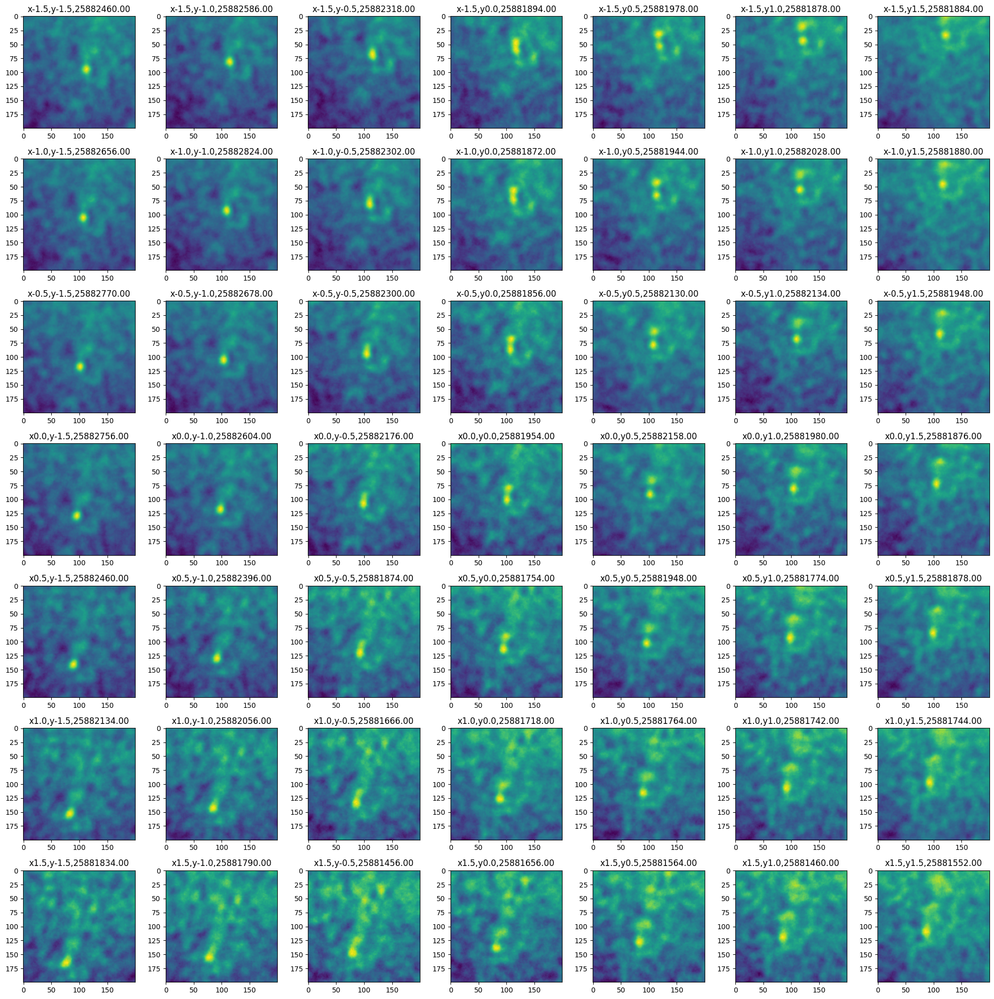

In [3]:
from libtilt.transformations import Rx, Ry, Rz, T
fig, axs = plt.subplots(7, 7, figsize=(20, 20))



for a1 in range(7):
    for a2 in range(7):
        a1a = (a1-3) * 0.5
        a2a = (a2-3) * 0.5
        new_matrix = matrices[TILT] @ Rx(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0]
        model_image = project_aunp_model_mine(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
        image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
        cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
        sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
        axs[a1,a2].imshow(sub_new.cpu().detach())
        axs[a1,a2].title.set_text(f'x{a1a:.1f},y{a2a:.1f},{sub_new.max().item():.2f}')
plt.tight_layout()
plt.show()

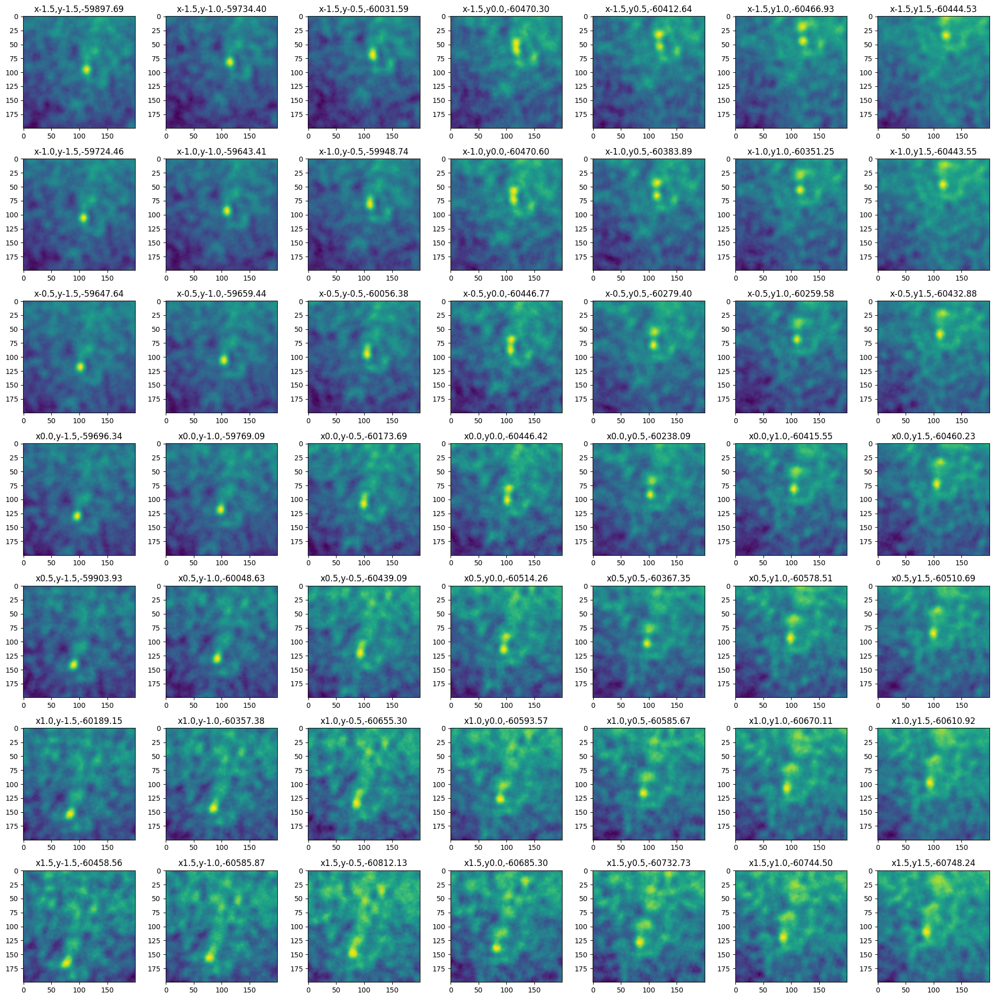

In [4]:
from libtilt.transformations import Rx, Ry, Rz, T
fig, axs = plt.subplots(7, 7, figsize=(20, 20))



for a1 in range(7):
    for a2 in range(7):
        a1a = (a1-3) * 0.5
        a2a = (a2-3) * 0.5
        new_matrix = matrices[TILT] @ Rx(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0]
        model_image, circle = project_aunp_model_libtilt(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
        model_image = model_image  * -1.0
        image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
        cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
        sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
        axs[a1,a2].imshow(sub_new.cpu().detach())
        axs[a1,a2].title.set_text(f'x{a1a:.1f},y{a2a:.1f},{sub_new.max().item():.2f}')
plt.tight_layout()
plt.show()

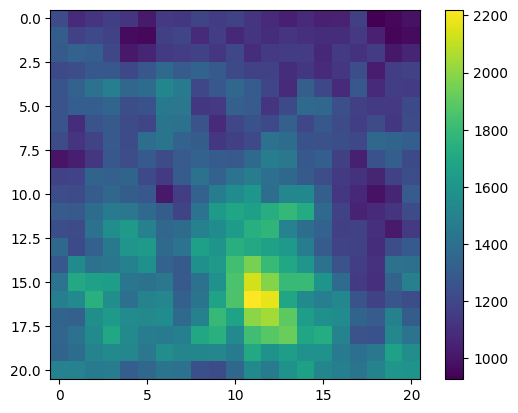

In [5]:
from libtilt.transformations import Rx, Ry, Rz, T
import numpy as np
#fig, axs = plt.subplots(11, 11, figsize=(20, 20))

TILT=0
scores = np.zeros((21,21))
for a1 in range(21):
    for a2 in range(21):
        a1a = (a1-10) * 0.5
        a2a = (a2-10) * 0.5
        new_matrix = Rx(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ matrices[TILT]
        model_image, c = project_aunp_model_libtilt(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
        model_image = model_image  * -1.0
        image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
        cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
        sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
        #axs[a1,a2].imshow(sub_new.cpu().detach())
        score = sub_new.max().item() - sub_new.median().item()
        scores[a1,a2] = score
        #axs[a1,a2].title.set_text(f'{score:.2f}')
        #axs[a1,a2].axis('off')
#plt.tight_layout()
#plt.show()
plt.imshow(scores)
plt.colorbar()
plt.show()

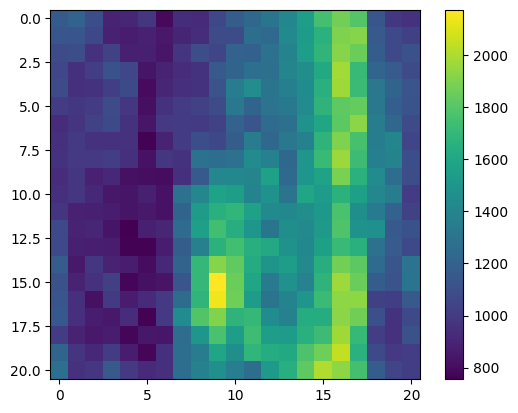

In [6]:
from libtilt.transformations import Rx, Ry, Rz, T
import numpy as np
#fig, axs = plt.subplots(11, 11, figsize=(20, 20))

TILT=0
scores = np.zeros((21,21))
for a1 in range(21):
    for a2 in range(21):
        a1a = (a1-10) * 0.5
        a2a = (a2-10) * 0.5
        new_matrix = Rx(a1a).to(device).double()[0] @ Rz(a2a).to(device).double()[0] @ matrices[TILT]
        model_image, c = project_aunp_model_libtilt(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
        model_image = model_image  * -1.0
        image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
        cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
        sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
        #axs[a1,a2].imshow(sub_new.cpu().detach())
        score = sub_new.max().item() - sub_new.median().item()
        scores[a1,a2] = score
        #axs[a1,a2].title.set_text(f'{score:.2f}')
        #axs[a1,a2].axis('off')
#plt.tight_layout()
#plt.show()
plt.imshow(scores)
plt.colorbar()
plt.show()

TypeError: unsupported operand type(s) for -: 'range' and 'int'

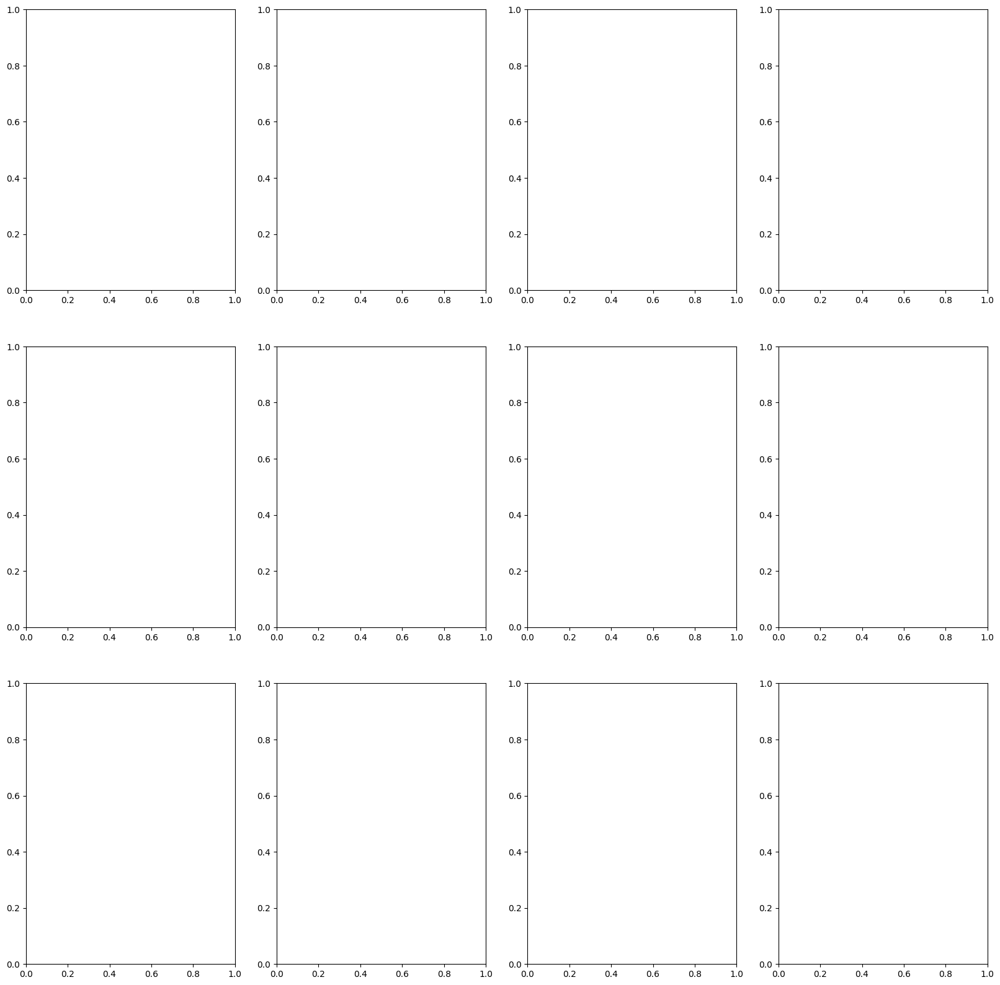

In [7]:
from libtilt.transformations import Rx, Ry, Rz, T
import numpy as np
fig, axs = plt.subplots(3, 4, figsize=(20, 20))

TILT=0
scores = np.zeros((11,11,11))
for a1 in [range(11)]:
    for a2 in range(11):
        for a3 in range(11):
            a1a = (a1-5) 
            a2a = (a2-5) 
            a3a = (a3-5)
            new_matrix = Rz(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ Rx(a3a).to(device).double()[0] @ matrices[TILT]
            model_image, c = project_aunp_model_libtilt(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
            model_image = model_image  * -1.0
            image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
            cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
            sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
            #axs[a1,a2].imshow(sub_new.cpu().detach())
            score = sub_new.max().item() - sub_new.median().item()
            scores[a1,a2,a3] = score
            if score > 2100:
                print(a1a,a2a,a3a,score)
            #axs[a1,a2].title.set_text(f'{score:.2f}')
            #axs[a1,a2].axis('off')
#plt.tight_layout()
#plt.show()
for i in range(11):
    axs.flatten()[i].imshow(scores[i],vmin=np.min(scores),vmax=np.max(scores))
#plt.colorbar()
plt.show()

tensor([[-1.0177e-01, -9.8733e-01,  1.2174e-01,  4.8041e+03],
        [ 6.7542e-01, -1.5842e-01, -7.2022e-01,  1.1682e+03],
        [ 7.3038e-01,  8.9301e-03,  6.8299e-01, -1.5517e+03],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64)


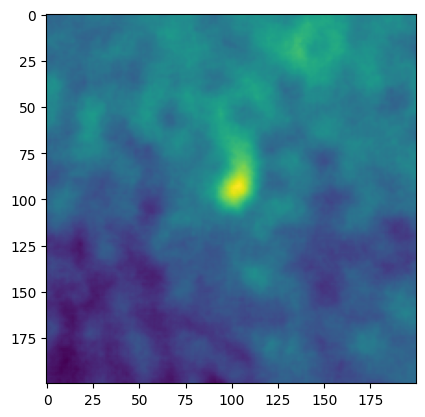

In [ ]:
a1a = 0
a2a = 1
a3a = 3
new_matrix = Rz(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ Rx(a3a).to(device).double()[0] @ matrices[TILT]
print(new_matrix)
model_image, c = project_aunp_model_libtilt(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
model_image = model_image  * -1.0
image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
plt.imshow(sub_new.cpu().detach())

tensor([[-1.8758e-01, -9.7662e-01,  1.0498e-01,  4.8448e+03],
        [ 7.2752e-01, -2.0994e-01, -6.5317e-01,  1.2911e+03],
        [ 6.5995e-01, -4.6144e-02,  7.4990e-01, -1.3089e+03],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64)


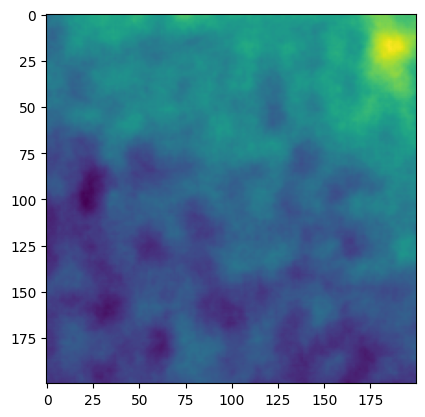

In [ ]:
a1a = 3
a2a = -3
a3a = -2
new_matrix = Rz(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ Rx(a3a).to(device).double()[0] @ matrices[TILT]
print(new_matrix)
model_image, c = project_aunp_model_libtilt(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
model_image = model_image  * -1.0
image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
plt.imshow(sub_new.cpu().detach())

tensor([[-1.0765e-01, -9.7471e-01,  1.9582e-01,  4.6491e+03],
        [ 7.4325e-01, -2.0972e-01, -6.3529e-01,  1.2534e+03],
        [ 6.6029e-01,  7.7155e-02,  7.4703e-01, -1.9148e+03],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64)


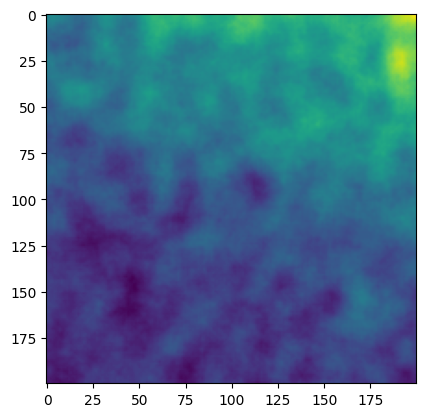

In [ ]:
a1a = 3
a2a = 4
a3a = -3
new_matrix = Rz(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ Rx(a3a).to(device).double()[0] @ matrices[TILT]
print(new_matrix)
model_image, c = project_aunp_model_libtilt(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
model_image = model_image  * -1.0
image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
plt.imshow(sub_new.cpu().detach())

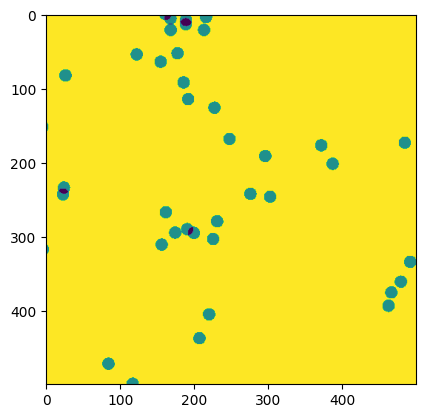

In [ ]:
model_image = project_aunp_model_mine(aunps, matrices[TILT], tilt_series.shape[1:], 8.3, device)
plt.imshow(model_image.cpu().detach()[1000:1500,1500:2000])


In [ ]:
%%timeit
#from findingampa.utils.projection import project_aunp_model_libtilt
#from importlib import reload
#import findingampa
#reload(findingampa)
model_image, circle = findingampa.utils.projection.project_aunp_model_libtilt(aunps, matrices[TILT], tilt_series.shape[1:], 8.3, device)

#plt.imshow(model_image.cpu().detach()[1000:1500,1500:2000])
#plt.show()
#plt.imshow(circle.cpu().detach())
#plt.show()


NameError: name 'findingampa' is not defined

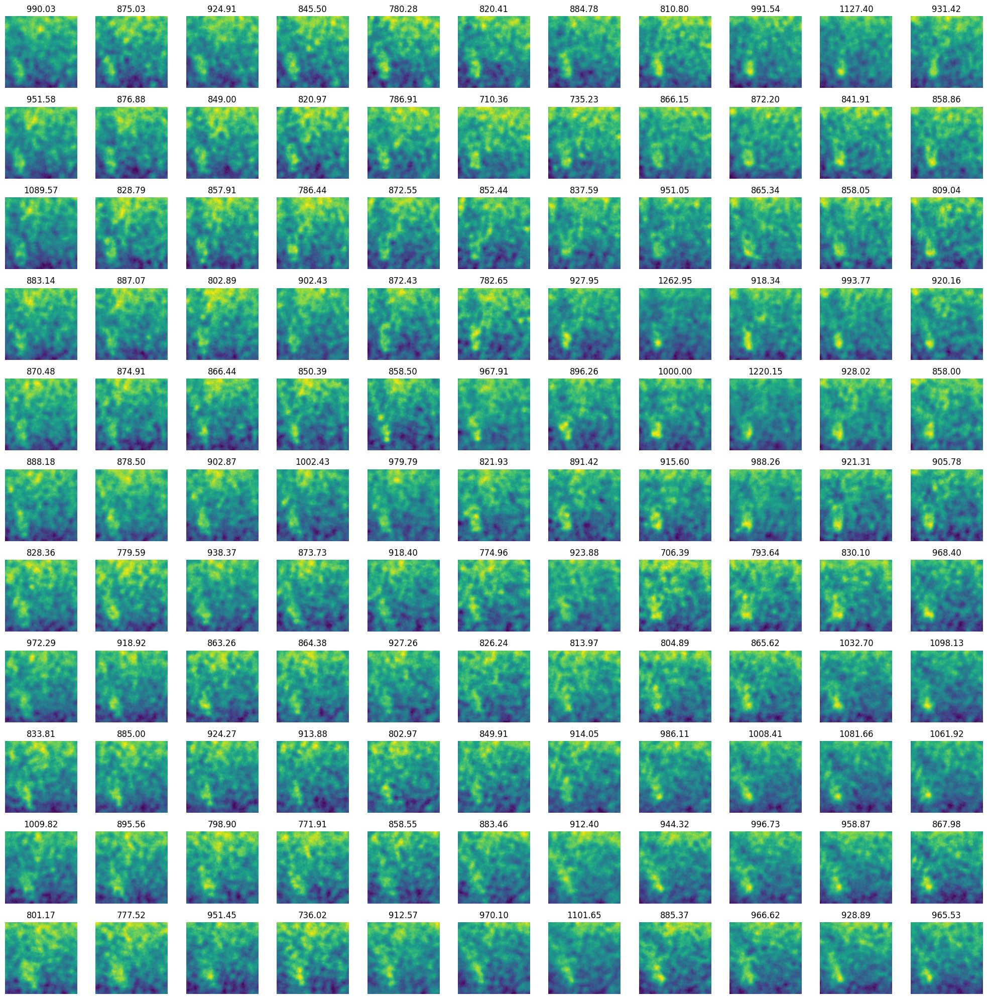

In [ ]:
from libtilt.transformations import Rx, Ry, Rz, T
import numpy as np
fig, axs = plt.subplots(11, 11, figsize=(20, 20))

TILT=0
scores = np.zeros((11,11,11))
for a1 in [3]:
    for a2 in range(11):
        for a3 in range(11):
            a1a = (a1-5) 
            a2a = (a2-5) 
            a3a = (a3-5)
            new_matrix = Rz(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ Rx(a3a).to(device).double()[0] @ matrices[TILT]
            model_image, c = project_aunp_model_libtilt(aunps, new_matrix, tilt_series.shape[1:], 8.3, device)
            model_image = model_image  * -1.0
            image_product = torch.fft.fft2(tilt_series[TILT]) * torch.fft.fft2(model_image).conj()
            cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
            sub_new = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
            axs[a2,a3].imshow(sub_new.cpu().detach())
            score = sub_new.max().item() - sub_new.median().item()
            scores[a1,a2,a3] = score
            if score > 2100:
                print(a1a,a2a,a3a,score)
            axs[a2,a3].title.set_text(f'{score:.2f}')
            axs[a2,a3].axis('off')
plt.tight_layout()
plt.show()
#for i in range(11):
#    axs.flatten()[i].imshow(scores[i],vmin=np.min(scores),vmax=np.max(scores))
#plt.colorbar()
#plt.show()

(2000.0, 3200.0)

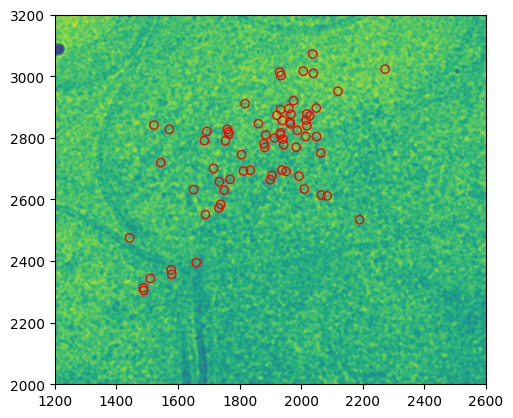

In [38]:
from skimage import exposure

# Assuming `image` is your image
# Contrast stretching
p2, p98 = np.percentile(tilt_series[TILT].cpu().numpy(), (2, 98))
img_rescale = exposure.rescale_intensity(tilt_series[TILT].cpu().numpy(), in_range=(p2, p98))

from scipy import ndimage

# Assuming `img_rescale` is your image
lowpass = ndimage.gaussian_filter(img_rescale, 3)

plt.imshow(lowpass, origin='lower')

a1a = 3
a2a = -3
a3a = -2
new_matrix = Rz(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ Rx(a3a).to(device).double()[0] @ matrices[TILT]
coordinate_projection = torch.mm(new_matrix, aunps.T).T[:,[0,1]].cpu().numpy()
plt.scatter(coordinate_projection[:, 0], coordinate_projection[:, 1],facecolor='none',edgecolors='red')
plt.xlim(1200,2600)
plt.ylim(2000,3200)


(2000.0, 3200.0)

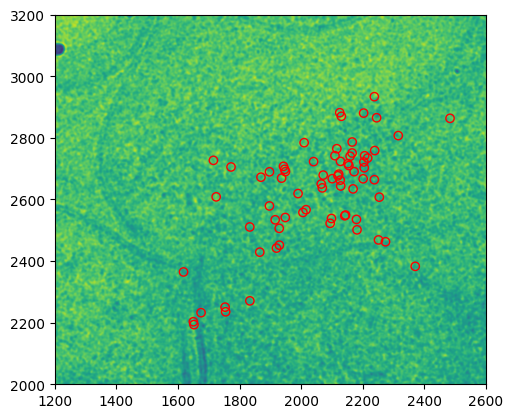

In [37]:
TILT=0
from skimage import exposure

# Assuming `image` is your image
# Contrast stretching
p2, p98 = np.percentile(tilt_series[TILT].cpu().numpy(), (2, 98))
img_rescale = exposure.rescale_intensity(tilt_series[TILT].cpu().numpy(), in_range=(p2, p98))

from scipy import ndimage

# Assuming `img_rescale` is your image
lowpass = ndimage.gaussian_filter(img_rescale, 3)

plt.imshow(lowpass, origin='lower')

a1a = 0
a2a = 0
a3a = 0
new_matrix = Rz(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ Rx(a3a).to(device).double()[0] @ matrices[TILT]
coordinate_projection = torch.mm(new_matrix, aunps.T).T[:,[0,1]].cpu().numpy()
plt.scatter(coordinate_projection[:, 0], coordinate_projection[:, 1],facecolor='none',edgecolors='red')
plt.xlim(1200,2600)
plt.ylim(2000,3200)


(2000.0, 3200.0)

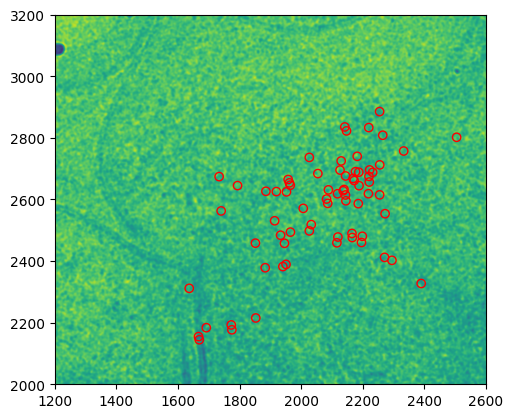

In [39]:
TILT=0
from skimage import exposure

# Assuming `image` is your image
# Contrast stretching
p2, p98 = np.percentile(tilt_series[TILT].cpu().numpy(), (2, 98))
img_rescale = exposure.rescale_intensity(tilt_series[TILT].cpu().numpy(), in_range=(p2, p98))

from scipy import ndimage

# Assuming `img_rescale` is your image
lowpass = ndimage.gaussian_filter(img_rescale, 3)

plt.imshow(lowpass, origin='lower')

a1a = 0
a2a = 1
a3a = 3
new_matrix = Rz(a1a).to(device).double()[0] @ Ry(a2a).to(device).double()[0] @ Rx(a3a).to(device).double()[0] @ matrices[TILT]
coordinate_projection = torch.mm(new_matrix, aunps.T).T[:,[0,1]].cpu().numpy()
plt.scatter(coordinate_projection[:, 0], coordinate_projection[:, 1],facecolor='none',edgecolors='red')
plt.xlim(1200,2600)
plt.ylim(2000,3200)
